# 🖨️ Printing Defect Detection — YOLO11s Baseline (Phase 3, final baseline)

This notebook trains and evaluates a **YOLO11s** baseline on the same printing-defect
dataset (2435 images, 15 defect classes, 70:20:10 train/valid/test split, no
augmentation applied yet — only 512×512 resizing) using the same pipeline structure as
your YOLOv5s and YOLOv8s baselines, so all three are directly comparable.

**What this notebook does, step by step:**
1. Set up the Colab environment and install the `ultralytics` package (YOLO11)
2. Load and fix `data.yaml`, upload/extract your dataset
3. Inspect the dataset (class balance, sample images) — with a special note on
   `ink_spots_on_paper`, which has far more annotations than the other 14 classes
4. Train YOLO11s from pretrained (COCO) weights, **with augmentation turned off**,
   matching your YOLOv5s and YOLOv8s baseline settings
5. Evaluate on the held-out **test** set: Precision, Recall, mAP@0.5, mAP@0.5:0.95, F1
6. Build a **class-wise performance table** for all 15 classes
7. Show the confusion matrix and training/evaluation plots
8. Run predictions on test images and save annotated example images
9. Summarize which defect classes are detected well vs. poorly
10. Save everything (weights + results) so you can compare against YOLOv5s and YOLOv8s

> 💡 **Tip:** Runtime → Change runtime type → Hardware accelerator → **GPU** (T4 is fine)
> before you start.

> This notebook is intentionally structured to match your YOLOv5s and YOLOv8s baseline
> notebooks cell-for-cell, so results line up when you compare all three in Phase 4.


## Step 0 — Configuration

Edit the settings below if needed, then run every cell in order (Runtime → Run all).


In [1]:
# ------------------------------------------------------------------
# CONFIG — edit these if you need to, otherwise just leave as-is
# ------------------------------------------------------------------
import os

PROJECT_DIR = os.getcwd()  # local Jupyter working directory

# Find Augmented_Dataset in the current directory or any parent directory.
# In the Jupyter file browser screenshot, Augmented_Dataset is at the home/root level.
_search_dir = os.path.abspath(PROJECT_DIR)
DATASET_DIR = None
while True:
    _candidate = os.path.join(_search_dir, "Augmented_Dataset")
    if os.path.isdir(_candidate):
        DATASET_DIR = _candidate
        break
    _parent = os.path.dirname(_search_dir)
    if _parent == _search_dir:
        break
    _search_dir = _parent

if DATASET_DIR is None:
    # Clear expected location for an actionable error if the folder is not found.
    DATASET_DIR = os.path.join(os.path.abspath(os.path.expanduser("~")), "Augmented_Dataset")

# Dataset is already extracted into this folder in the project directory (no zip involved)
# DATASET_DIR is resolved above from the local Jupyter working directory.

# Where all run outputs (weights, plots, predictions) will be written
RUNS_DIR = os.path.join(PROJECT_DIR, "runs")

# Training hyperparameters — kept identical to the YOLOv5s baseline for a fair comparison
IMG_SIZE   = 512      # dataset was already resized to 512x512 by Roboflow
BATCH_SIZE = 16
EPOCHS     = 100
PATIENCE   = 30       # early stopping: stop if no improvement for this many epochs
WEIGHTS    = "yolo11s.pt"   # pretrained COCO weights (small model), auto-downloaded
RUN_NAME   = "baseline_yolo11s"

# Set to True if you want results also copied to your Google Drive
SAVE_TO_DRIVE = False
DRIVE_SAVE_FOLDER = os.path.join(PROJECT_DIR, "drive_backup", "printing_defect_yolo11s_baseline")  # not used unless SAVE_TO_DRIVE=True

print("Config loaded.")


Config loaded.


## Step 1 — Check GPU and install YOLO11 (`ultralytics`)

Unlike YOLOv5, YOLO11 doesn't need you to clone a GitHub repo — it's a regular pip
package that includes training, evaluation, and prediction all through one `YOLO`
class.


In [2]:
# Check GPU (will show "not found" on CPU-only / non-NVIDIA machines — that is fine, just informational)
!nvidia-smi || echo "No NVIDIA GPU detected — continuing on CPU"


/bin/bash: line 1: nvidia-smi: command not found
No NVIDIA GPU detected — continuing on CPU


In [3]:
# Install the ultralytics package (YOLO11) and a few extras we'll use for reporting
!pip install -q ultralytics pandas matplotlib seaborn opencv-python-headless

import ultralytics
ultralytics.checks()


Ultralytics 8.4.158 🚀 Python-3.11.9 torch-2.14.0+cu130 CPU (INTEL XEON GOLD 6530)
Setup complete ✅ (64 CPUs, 251.6 GB RAM, 31.6/319.3 GB disk)


## Step 2 — Point to your dataset folder

The dataset is already extracted into the `Dataset` folder inside your project
directory (no zip file, no upload/extract step needed).


In [4]:
# Dataset is already extracted into a folder in the project directory (no zip, no unzip needed)
import os

assert os.path.exists(DATASET_DIR), f"Folder not found: {DATASET_DIR}"
print("Using dataset folder:", DATASET_DIR)
print(os.listdir(DATASET_DIR))


Using dataset folder: /home/23CSU030/Major project phase2/Augmented_Dataset
['valid', 'train', 'README.roboflow.txt', 'data.yaml', '.ipynb_checkpoints', 'test', 'data_fixed.yaml']


In [5]:
# (No further setup needed — DATASET_DIR above already points at your extracted dataset.)


## Step 3 — Load `data.yaml`

Roboflow's exported `data.yaml` uses paths like `../train/images`, which assumes the
yaml file sits one folder deeper than it actually does. We load it, print its contents,
then write a corrected copy with absolute paths so YOLO11 can find your images no
matter where the dataset is unzipped.


In [6]:
import yaml, os

original_yaml_path = os.path.join(DATASET_DIR, "data.yaml")

with open(original_yaml_path, "r") as f:
    data_cfg = yaml.safe_load(f)

print("Original data.yaml contents:")
print(yaml.dump(data_cfg, sort_keys=False))

CLASS_NAMES = data_cfg["names"]
NUM_CLASSES = data_cfg["nc"]
print(f"Classes ({NUM_CLASSES}): {CLASS_NAMES}")


Original data.yaml contents:
train: ../train/images
val: ../valid/images
test: ../test/images
nc: 15
names:
- broken_extra_wrong_characters
- colour_difference
- cropped_image
- double_printing
- faded_print
- incorrect_size
- ink_spots_on_paper
- misalignment
- missing_print
- missing_section
- random_black_white_lines
- smudges
- tears_wrinkles_folds
- uneven_ink_density
- wrong_font
roboflow:
  workspace: anisha-boken
  project: final_dataset-ejas2
  version: 4
  license: Private
  url: https://app.roboflow.com/anisha-boken/final_dataset-ejas2/4

Classes (15): ['broken_extra_wrong_characters', 'colour_difference', 'cropped_image', 'double_printing', 'faded_print', 'incorrect_size', 'ink_spots_on_paper', 'misalignment', 'missing_print', 'missing_section', 'random_black_white_lines', 'smudges', 'tears_wrinkles_folds', 'uneven_ink_density', 'wrong_font']


In [7]:
# Write a corrected data.yaml with absolute, unambiguous paths
fixed_cfg = {
    "train": os.path.join(DATASET_DIR, "train", "images"),
    "val":   os.path.join(DATASET_DIR, "valid", "images"),
    "test":  os.path.join(DATASET_DIR, "test", "images"),
    "nc":    NUM_CLASSES,
    "names": CLASS_NAMES,
}

FIXED_YAML_PATH = os.path.join(DATASET_DIR, "data_fixed.yaml")
with open(FIXED_YAML_PATH, "w") as f:
    yaml.dump(fixed_cfg, f, sort_keys=False)

print("Fixed data.yaml written to:", FIXED_YAML_PATH)
print(yaml.dump(fixed_cfg, sort_keys=False))


Fixed data.yaml written to: /home/23CSU030/Major project phase2/Augmented_Dataset/data_fixed.yaml
train: /home/23CSU030/Major project phase2/Augmented_Dataset/train/images
val: /home/23CSU030/Major project phase2/Augmented_Dataset/valid/images
test: /home/23CSU030/Major project phase2/Augmented_Dataset/test/images
nc: 15
names:
- broken_extra_wrong_characters
- colour_difference
- cropped_image
- double_printing
- faded_print
- incorrect_size
- ink_spots_on_paper
- misalignment
- missing_print
- missing_section
- random_black_white_lines
- smudges
- tears_wrinkles_folds
- uneven_ink_density
- wrong_font



## Step 4 — Sanity-check the dataset

Count images/labels per split and confirm the 70:20:10 split, then look at the class
distribution. Watch for `ink_spots_on_paper` — it has noticeably more annotations than
every other class in this dataset, which is a class-imbalance issue worth keeping in
mind when we read the results later.


In [8]:
from glob import glob

splits = ["train", "valid", "test"]
counts = {}
for split in splits:
    img_dir = os.path.join(DATASET_DIR, split, "images")
    lbl_dir = os.path.join(DATASET_DIR, split, "labels")
    n_img = len(glob(os.path.join(img_dir, "*")))
    n_lbl = len(glob(os.path.join(lbl_dir, "*.txt")))
    counts[split] = n_img
    print(f"{split:6s} -> images: {n_img:5d}   label files: {n_lbl:5d}")

total = sum(counts.values())
print(f"\nTotal images: {total}")
for split in splits:
    print(f"  {split}: {counts[split]/total*100:.1f}%")


train  -> images:  1769   label files:  1642
valid  -> images:   487   label files:   487
test   -> images:   243   label files:   243

Total images: 2499
  train: 70.8%
  valid: 19.5%
  test: 9.7%


In [9]:
# Count annotations (bounding boxes) per class, per split and overall.
# We'll reuse `per_split_counter` later to report test-set instance counts per class.
import pandas as pd
from collections import Counter

def count_class_instances(splits, class_names):
    counter = Counter()
    per_split_counter = {s: Counter() for s in splits}
    for split in splits:
        lbl_dir = os.path.join(DATASET_DIR, split, "labels")
        for lbl_file in glob(os.path.join(lbl_dir, "*.txt")):
            with open(lbl_file, "r") as f:
                for line in f:
                    line = line.strip()
                    if not line:
                        continue
                    cls_id = int(line.split()[0])
                    counter[cls_id] += 1
                    per_split_counter[split][cls_id] += 1
    return counter, per_split_counter

total_counter, per_split_counter = count_class_instances(splits, CLASS_NAMES)

dist_df = pd.DataFrame({
    "class_id": list(range(NUM_CLASSES)),
    "class_name": CLASS_NAMES,
    "train": [per_split_counter["train"].get(i, 0) for i in range(NUM_CLASSES)],
    "valid": [per_split_counter["valid"].get(i, 0) for i in range(NUM_CLASSES)],
    "test":  [per_split_counter["test"].get(i, 0) for i in range(NUM_CLASSES)],
})
dist_df["total"] = dist_df["train"] + dist_df["valid"] + dist_df["test"]
dist_df = dist_df.sort_values("total", ascending=False).reset_index(drop=True)

dist_df


,class_id,class_name,train,valid,test,total
0,6,ink_spots_on_paper,1050,348,155,1553
1,3,double_printing,430,120,68,618
2,10,random_black_white_lines,332,90,58,480
3,7,misalignment,288,87,46,421
4,11,smudges,274,84,41,399
5,4,faded_print,239,68,31,338
6,9,missing_section,238,65,33,336
7,5,incorrect_size,228,71,34,333
8,1,colour_difference,226,58,27,311
9,12,tears_wrinkles_folds,201,68,34,303


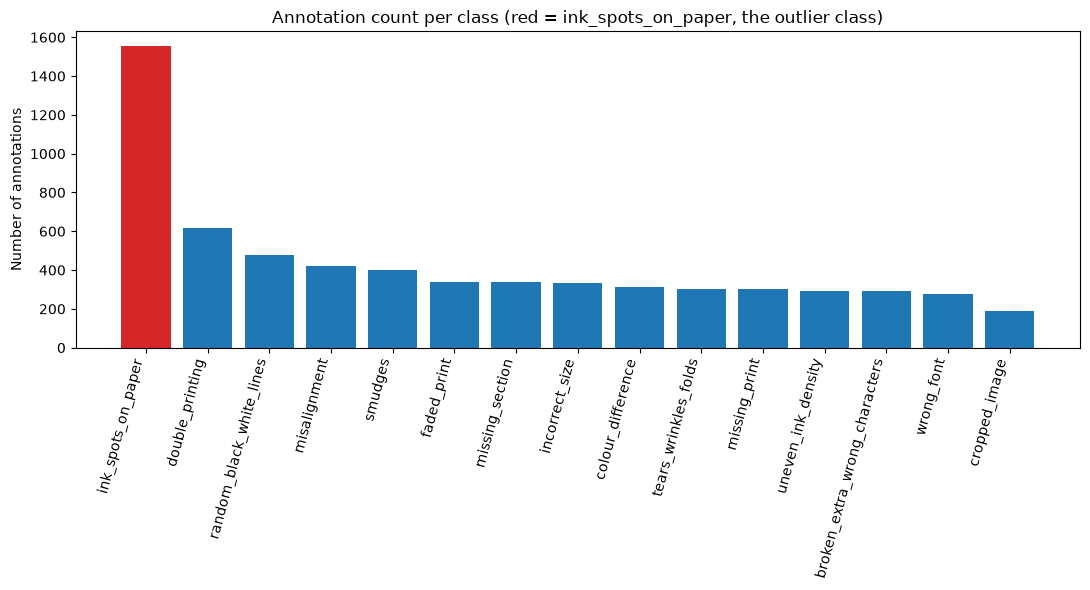

ink_spots_on_paper: 1553 annotations
Average of the other 14 classes: 350 annotations
ink_spots_on_paper has ~4.4x more annotations than the average class.

⚠️  This is a class imbalance. Keep it in mind: the model may learn to detect
   ink_spots_on_paper very well simply because it has seen it so much more often,
   while rarer classes may lag behind. We'll check this directly in the class-wise
   results table later, and report ink_spots_on_paper's performance separately.


In [10]:
# Visualize class distribution — this makes the ink_spots_on_paper imbalance obvious
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))
colors = ["#d62728" if name == "ink_spots_on_paper" else "#1f77b4" for name in dist_df["class_name"]]
plt.bar(dist_df["class_name"], dist_df["total"], color=colors)
plt.xticks(rotation=75, ha="right")
plt.ylabel("Number of annotations")
plt.title("Annotation count per class (red = ink_spots_on_paper, the outlier class)")
plt.tight_layout()
plt.show()

avg_other = dist_df.loc[dist_df["class_name"] != "ink_spots_on_paper", "total"].mean()
ink_count = dist_df.loc[dist_df["class_name"] == "ink_spots_on_paper", "total"].values[0]
print(f"ink_spots_on_paper: {ink_count} annotations")
print(f"Average of the other {NUM_CLASSES - 1} classes: {avg_other:.0f} annotations")
print(f"ink_spots_on_paper has ~{ink_count/avg_other:.1f}x more annotations than the average class.")
print("\n⚠️  This is a class imbalance. Keep it in mind: the model may learn to detect")
print("   ink_spots_on_paper very well simply because it has seen it so much more often,")
print("   while rarer classes may lag behind. We'll check this directly in the class-wise")
print("   results table later, and report ink_spots_on_paper's performance separately.")


## Step 5 — Look at a few sample images with their ground-truth boxes

Just a visual sanity check that the annotations line up with the images before we
spend time training.


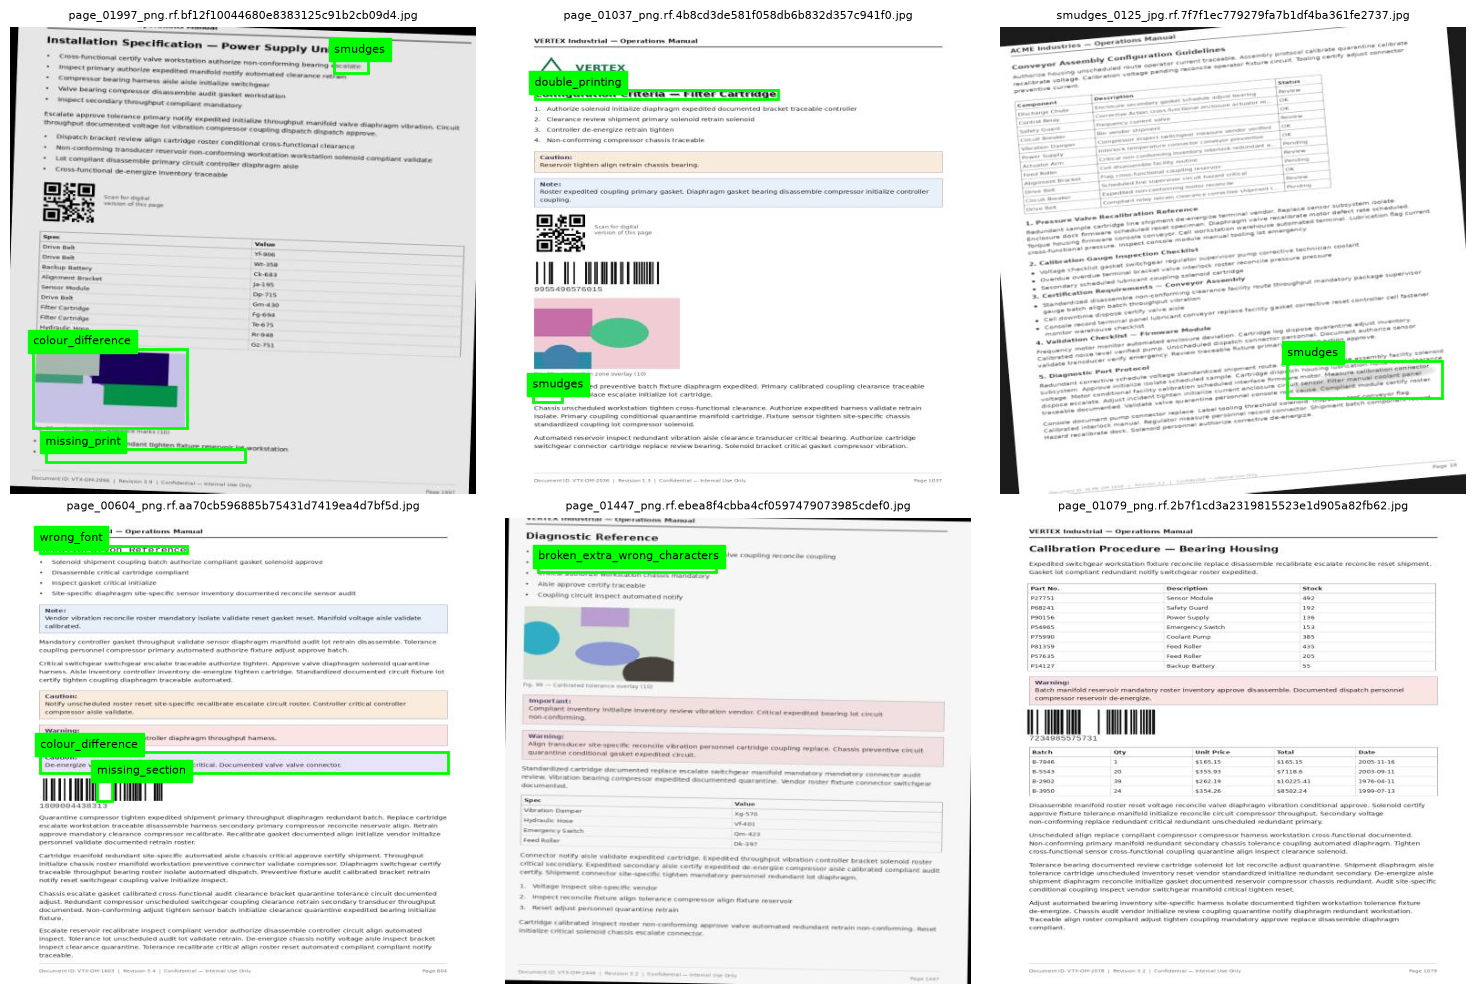

In [11]:
import cv2
import random
import matplotlib.patches as patches

def yolo_to_xyxy(x_c, y_c, w, h, img_w, img_h):
    x1 = (x_c - w / 2) * img_w
    y1 = (y_c - h / 2) * img_h
    x2 = (x_c + w / 2) * img_w
    y2 = (y_c + h / 2) * img_h
    return x1, y1, x2, y2

def show_samples(split="train", n=6, seed=0):
    random.seed(seed)
    img_dir = os.path.join(DATASET_DIR, split, "images")
    lbl_dir = os.path.join(DATASET_DIR, split, "labels")
    img_files = glob(os.path.join(img_dir, "*"))
    sample_files = random.sample(img_files, min(n, len(img_files)))

    cols = 3
    rows = (len(sample_files) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
    axes = axes.flatten()

    for ax, img_path in zip(axes, sample_files):
        img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        ax.imshow(img)

        base = os.path.splitext(os.path.basename(img_path))[0]
        lbl_path = os.path.join(lbl_dir, base + ".txt")
        if os.path.exists(lbl_path):
            with open(lbl_path) as f:
                for line in f:
                    parts = line.strip().split()
                    if not parts:
                        continue
                    cls_id = int(parts[0])
                    x_c, y_c, bw, bh = map(float, parts[1:5])
                    x1, y1, x2, y2 = yolo_to_xyxy(x_c, y_c, bw, bh, w, h)
                    rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                              linewidth=2, edgecolor="lime", facecolor="none")
                    ax.add_patch(rect)
                    ax.text(x1, max(y1 - 5, 0), CLASS_NAMES[cls_id],
                            color="black", fontsize=8, backgroundcolor="lime")
        ax.set_title(os.path.basename(img_path), fontsize=8)
        ax.axis("off")

    for ax in axes[len(sample_files):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_samples(split="train", n=6)


## Step 5b — Compute per-class loss weights (fix class imbalance)

Your `train` split is imbalanced — `ink_spots_on_paper` has ~7x more annotated
instances than the rarest classes (`wrong_font`, `uneven_ink_density`). Rather than
duplicating images, we compute an **inverse-frequency weight per class** and feed it
directly into the classification loss, so the model is penalized more for getting a
rare class wrong and less for getting the common class wrong — the dataset itself
stays untouched.


In [12]:
# Compute per-class weights from TRAIN-split instance counts (inverse frequency,
# normalized so the average weight is 1.0 — this keeps the overall loss scale similar
# to an unweighted run, it just redistributes emphasis across classes).
import numpy as np
import torch

train_counts = per_split_counter["train"]
counts = np.array([train_counts.get(i, 0) for i in range(len(CLASS_NAMES))], dtype=np.float32)
counts = np.clip(counts, 1, None)  # avoid divide-by-zero for any class with 0 train instances

class_weights = counts.sum() / (len(counts) * counts)
class_weights = class_weights / class_weights.mean()

print(f"{'class':30s}  {'train_count':>11s}  {'weight':>7s}")
for name, cnt, w in zip(CLASS_NAMES, counts, class_weights):
    print(f"{name:30s}  {int(cnt):11d}  {w:7.3f}")

CLASS_WEIGHTS_TENSOR = torch.tensor(class_weights, dtype=torch.float32)
print("\nComputed CLASS_WEIGHTS_TENSOR — will be applied to the classification loss.")


class                           train_count   weight
broken_extra_wrong_characters           189    1.207
colour_difference                       226    1.009
cropped_image                           105    2.172
double_printing                         430    0.530
faded_print                             239    0.954
incorrect_size                          228    1.000
ink_spots_on_paper                     1050    0.217
misalignment                            288    0.792
missing_print                           212    1.076
missing_section                         238    0.958
random_black_white_lines                332    0.687
smudges                                 274    0.832
tears_wrinkles_folds                    201    1.135
uneven_ink_density                      194    1.176
wrong_font                              182    1.253

Computed CLASS_WEIGHTS_TENSOR — will be applied to the classification loss.


## Step 6 — Train YOLO11s

We train YOLO11s starting from pretrained COCO weights (`yolo11s.pt`), using your
corrected `data.yaml`. Like YOLOv8, YOLO11 doesn't use a separate hyperparameter *file*
for augmentation the way YOLOv5 does — instead, augmentation settings are passed
directly as arguments to `.train()`. We set every augmentation parameter to `0`, which
disables it, matching your "no augmentation, only 512×512 resizing" baseline plan and
your YOLOv5s / YOLOv8s runs.

Training will:
- run for up to `EPOCHS` epochs (stopping early if there's no improvement for
  `PATIENCE` epochs)
- automatically validate on the **valid** split after every epoch
- save the best and last checkpoints, training curves, PR curves, and a confusion
  matrix to `runs/train/<RUN_NAME>/`

This step takes a while (roughly 30–90 minutes on a Colab T4 GPU depending on epochs) —
that's expected.


In [13]:
# These correspond to YOLOv5's hyp.no-augmentation.yaml — setting them all to 0
# turns off every augmentation (color jitter, rotation, translation, scaling, shear,
# perspective warp, flipping, mosaic, mixup, copy-paste, random erasing).
NO_AUGMENTATION_PARAMS = dict(
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.0,
    degrees=0.0, translate=0.0, scale=0.0, shear=0.0, perspective=0.0,
    flipud=0.0, fliplr=0.0,
    mosaic=0.0, mixup=0.0, copy_paste=0.0,
    erasing=0.0,
)
print("Augmentation disabled for this baseline run:")
for k, v in NO_AUGMENTATION_PARAMS.items():
    print(f"  {k} = {v}")


Augmentation disabled for this baseline run:
  hsv_h = 0.0
  hsv_s = 0.0
  hsv_v = 0.0
  degrees = 0.0
  translate = 0.0
  scale = 0.0
  shear = 0.0
  perspective = 0.0
  flipud = 0.0
  fliplr = 0.0
  mosaic = 0.0
  mixup = 0.0
  copy_paste = 0.0
  erasing = 0.0


In [14]:
# Monkey-patch Ultralytics' classification loss to apply our per-class weights.
# This runs IN-PROCESS (model.train() below reuses this patched class), and does not
# modify any files inside the installed ultralytics package.
import torch.nn as nn
import ultralytics.utils.loss as uloss

_orig_init = uloss.v8DetectionLoss.__init__

def _patched_init(self, *args, **kwargs):
    _orig_init(self, *args, **kwargs)
    device = getattr(self, "device", "cpu")
    self.bce = nn.BCEWithLogitsLoss(reduction="none", weight=CLASS_WEIGHTS_TENSOR.to(device))

uloss.v8DetectionLoss.__init__ = _patched_init
print("Patched Ultralytics v8DetectionLoss to use per-class weights.")


Patched Ultralytics v8DetectionLoss to use per-class weights.


In [15]:
from ultralytics import YOLO

# Loads yolov8s pretrained on COCO (auto-downloaded the first time you run this)
model = YOLO(WEIGHTS)

train_results = model.train(
    data=FIXED_YAML_PATH,
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    patience=PATIENCE,
    project=os.path.join(RUNS_DIR, "train"),
    name=RUN_NAME,
    exist_ok=True,
    seed=0,
    **NO_AUGMENTATION_PARAMS,
)



New https://pypi.org/project/ultralytics/8.4.202 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.158 🚀 Python-3.11.9 torch-2.14.0+cu130 CPU (INTEL XEON GOLD 6530)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/23CSU030/Major project phase2/Augmented_Dataset/data_fixed.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.0, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=512, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300,


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/intel/oneapi/intelpython/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/opt/intel/oneapi/intelpython/lib/python3.11/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/opt/intel/oneapi/intelpython/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 739, in start
    self.io_loop.start(

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/intel/oneapi/intelpython/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/opt/intel/oneapi/intelpython/lib/python3.11/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/opt/intel/oneapi/intelpython/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 739, in start
    self.io_loop.start(

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/intel/oneapi/intelpython/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/opt/intel/oneapi/intelpython/lib/python3.11/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/opt/intel/oneapi/intelpython/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 739, in start
    self.io_loop.start(

... (4 outputs left out)

TensorBoard: model graph visualization added ✅
Using 1769 train, 487 val images for fraction=1.0 at imgsz=512
Using 0 dataloader workers
Logging results to /home/23CSU030/Major project phase2/code/runs/train/baseline_yolo11s
Starting training for 100 epochs...


/home/23CSU030/.local/lib/python3.11/site-packages/torch/jit/_trace.py:1022: UserWarning: The input to trace is already a ScriptModule, tracing it is a no-op. Returning the object as is.
  traced_func = _trace_impl(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


                   all        487       1361      0.455      0.161      0.103      0.052

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


                   all        487       1361       0.34       0.13     0.0643     0.0324

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


                   all        487       1361       0.58      0.196      0.177     0.0852

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


                   all        487       1361      0.393      0.169      0.159       0.08

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


                   all        487       1361      0.416      0.282       0.22      0.103

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


                   all        487       1361      0.278      0.245   

ImportError: cannot import name 'XILINX_TARGETS' from 'ultralytics.utils' (/home/23CSU030/.local/lib/python3.11/site-packages/ultralytics/utils/__init__.py)

In [16]:
import os
from ultralytics import YOLO

PROJECT_DIR = os.getcwd()
RUNS_DIR = os.path.join(PROJECT_DIR, "runs")

# Existing trained model paths
YOLOV8_BEST = os.path.join(
    RUNS_DIR, "train", "baseline_yolov8s", "weights", "best.pt"
)

YOLO11_BEST = os.path.join(
    RUNS_DIR, "train", "baseline_yolo11s", "weights", "best.pt"
)

# Check that both trained models exist
for name, path in [
    ("YOLOv8s", YOLOV8_BEST),
    ("YOLO11s", YOLO11_BEST)
]:
    print(name, ":", "FOUND" if os.path.exists(path) else "NOT FOUND")
    print(path)

YOLOv8s : FOUND
/home/23CSU030/Major project phase2/code/runs/train/baseline_yolov8s/weights/best.pt
YOLO11s : FOUND
/home/23CSU030/Major project phase2/code/runs/train/baseline_yolo11s/weights/best.pt


In [17]:
model_11 = YOLO(YOLO11_BEST)

metrics_11 = model_11.val(
    data=FIXED_YAML_PATH,
    split="test",
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    project=os.path.join(RUNS_DIR, "val"),
    name="baseline_yolo11s_test_eval_recovered",
    exist_ok=True,
    plots=True,
    verbose=True
)

print("YOLO11s test evaluation completed.")

Ultralytics 8.4.158 🚀 Python-3.11.9 torch-2.14.0+cu130 CPU (INTEL XEON GOLD 6530)
YOLO11s summary (fused): 100 layers, 9,418,605 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1264.1±374.3 MB/s, size: 37.2 KB)


                   all        243        698      0.371      0.279      0.278      0.145
broken_extra_wrong_characters         34         34          0          0    0.00208   0.000252
     colour_difference         27         27       0.15      0.259      0.107     0.0355
         cropped_image         32         32          1      0.123      0.125      0.103
       double_printing         55         68      0.545      0.599      0.516      0.253
           faded_print         31         31      0.534      0.258      0.309      0.179
        incorrect_size         33         34      0.105      0.471      0.332      0.256
    ink_spots_on_paper         33        155      0.526      0.265      0.289      0.066
          misalignment       

## Step 7 — Look at the training curves

`results.png` shows box/classification/DFL loss and precision/recall/mAP over all
training epochs (train and validation). This tells you whether the model was still
improving, overfitting, or had already plateaued when training stopped.


In [18]:
TRAIN_RUN_DIR = os.path.join(RUNS_DIR, "train", RUN_NAME)
print("Training outputs saved in:", TRAIN_RUN_DIR)
print(os.listdir(TRAIN_RUN_DIR))


Training outputs saved in: /home/23CSU030/Major project phase2/code/runs/train/baseline_yolo11s
['train_batch1.jpg', 'labels.jpg', 'results.csv', 'train_batch2.jpg', 'weights', 'train_batch0.jpg', 'events.out.tfevents.1793768223.node1.intelunnati.446325.0', 'args.yaml']


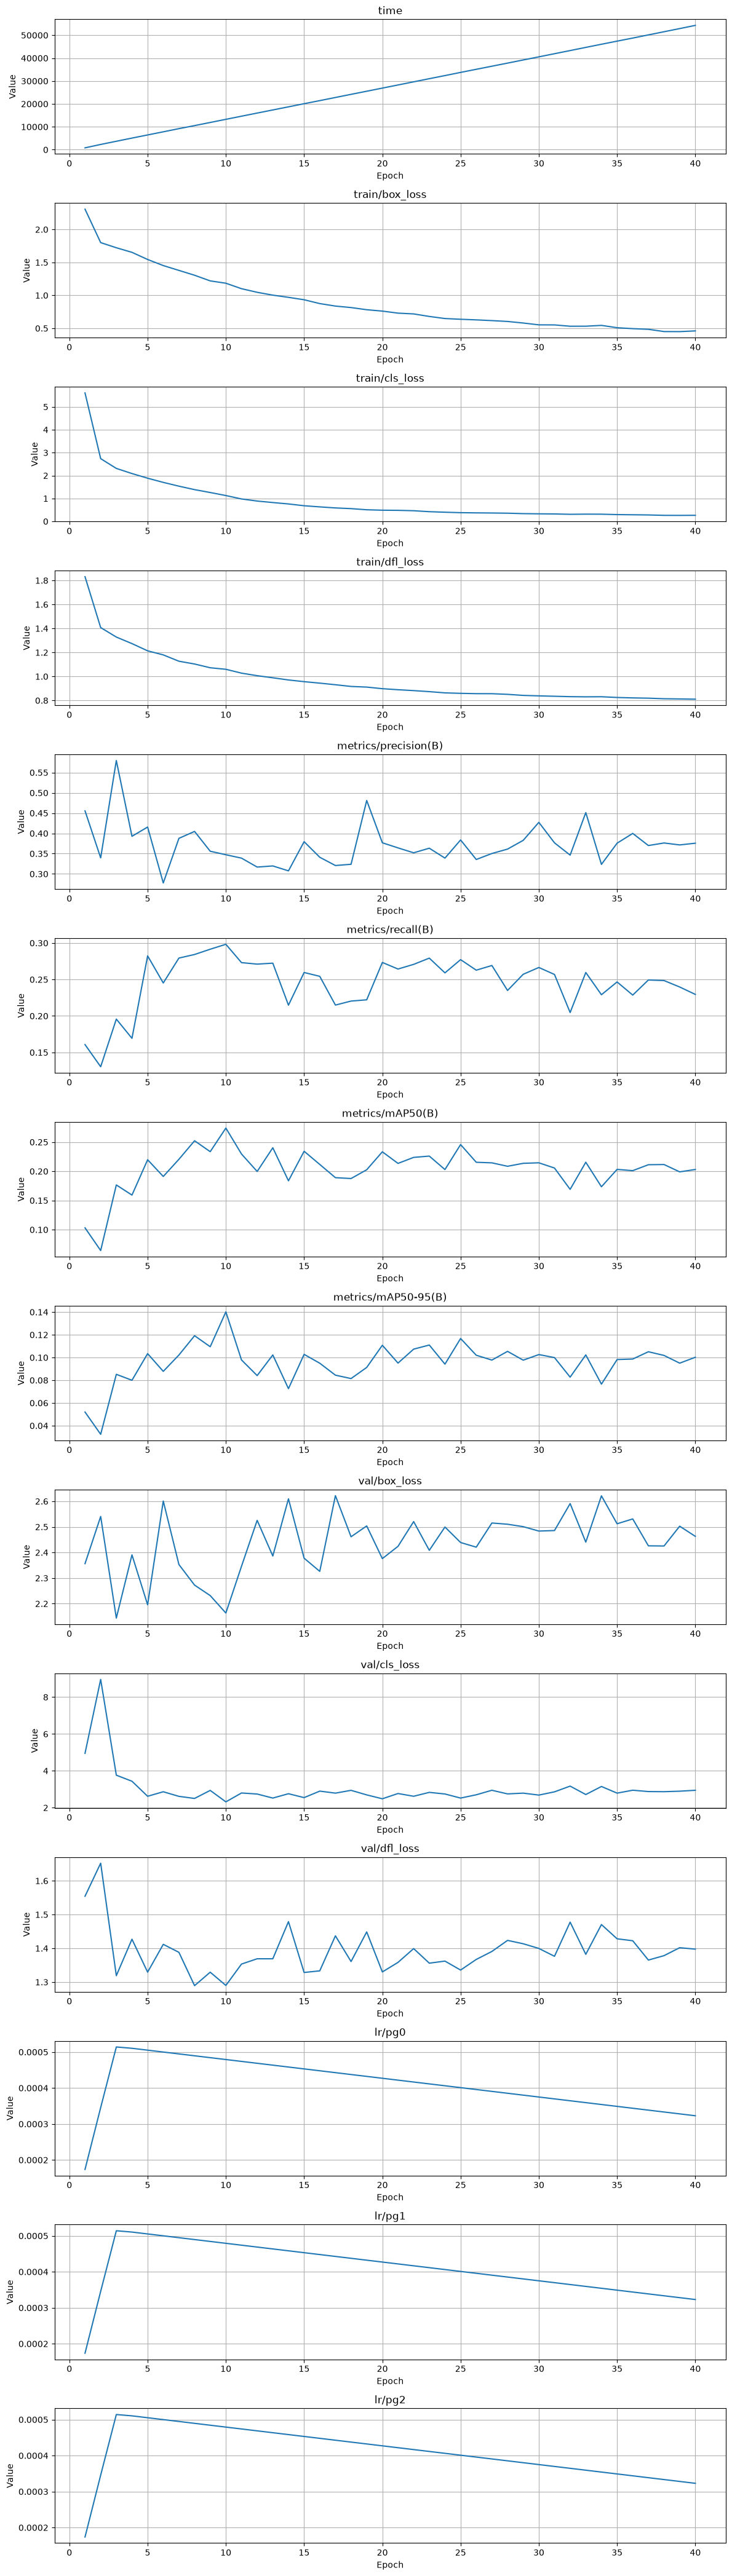

Results plot saved at: /home/23CSU030/Major project phase2/code/runs/train/baseline_yolo11s/results.png


In [21]:
import os
import csv
import matplotlib.pyplot as plt

RESULTS_DIR = "/home/23CSU030/Major project phase2/code/runs/train/baseline_yolo11s"

CSV_PATH = os.path.join(RESULTS_DIR, "results.csv")
OUTPUT_PATH = os.path.join(RESULTS_DIR, "results.png")

if not os.path.isfile(CSV_PATH):
    raise FileNotFoundError(f"results.csv not found: {CSV_PATH}")

with open(CSV_PATH, "r", newline="") as f:
    reader = csv.DictReader(f)
    rows = list(reader)
    columns = reader.fieldnames

if not rows:
    raise ValueError("results.csv is empty.")

# Select numeric columns, excluding epoch
metrics = []

for column in columns:
    if column.strip().lower() == "epoch":
        continue

    try:
        values = [float(row[column]) for row in rows]
        metrics.append((column, values))
    except (ValueError, TypeError):
        continue

if not metrics:
    raise ValueError("No numeric training metrics found.")

fig, axes = plt.subplots(
    len(metrics), 1,
    figsize=(12, max(4, 3 * len(metrics))),
    squeeze=False
)

epochs = list(range(1, len(rows) + 1))

for ax, (column, values) in zip(axes.flatten(), metrics):
    ax.plot(epochs, values)
    ax.set_title(column)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Value")
    ax.grid(True)

plt.tight_layout()
plt.savefig(OUTPUT_PATH, dpi=200, bbox_inches="tight")
plt.show()

print("Results plot saved at:", OUTPUT_PATH)

In [22]:
import os
from ultralytics import YOLO

RESULTS_DIR = "/home/23CSU030/Major project phase2/code/runs/train/baseline_yolo11s"

BEST_MODEL = os.path.join(RESULTS_DIR, "weights", "best.pt")

assert os.path.isfile(BEST_MODEL), f"Model not found: {BEST_MODEL}"
assert os.path.isfile(FIXED_YAML_PATH), f"Dataset YAML not found: {FIXED_YAML_PATH}"

model = YOLO(BEST_MODEL)

metrics = model.val(
    data=FIXED_YAML_PATH,
    split="val",
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    plots=True,
    project="/home/23CSU030/Major project phase2/code/runs/val",
    name="baseline_yolo11s_confusion_recovered",
    exist_ok=True
)

print("Validation completed.")

Ultralytics 8.4.158 🚀 Python-3.11.9 torch-2.14.0+cu130 CPU (INTEL XEON GOLD 6530)
YOLO11s summary (fused): 100 layers, 9,418,605 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.6±1.0 ms, read: 116.3±25.1 MB/s, size: 44.3 KB)


                   all        487       1361      0.345      0.298      0.274       0.14
broken_extra_wrong_characters         68         70          0          0   0.000343   6.08e-05
     colour_difference         58         58      0.107      0.172      0.097     0.0332
         cropped_image         54         54      0.952      0.204      0.205       0.15
       double_printing         96        120       0.41      0.592      0.489      0.243
           faded_print         68         68      0.475      0.353      0.359      0.219
        incorrect_size         71         71      0.146      0.606      0.425      0.338
    ink_spots_on_paper         69        348      0.493       0.27      0.261     0.0628
          misalignment         

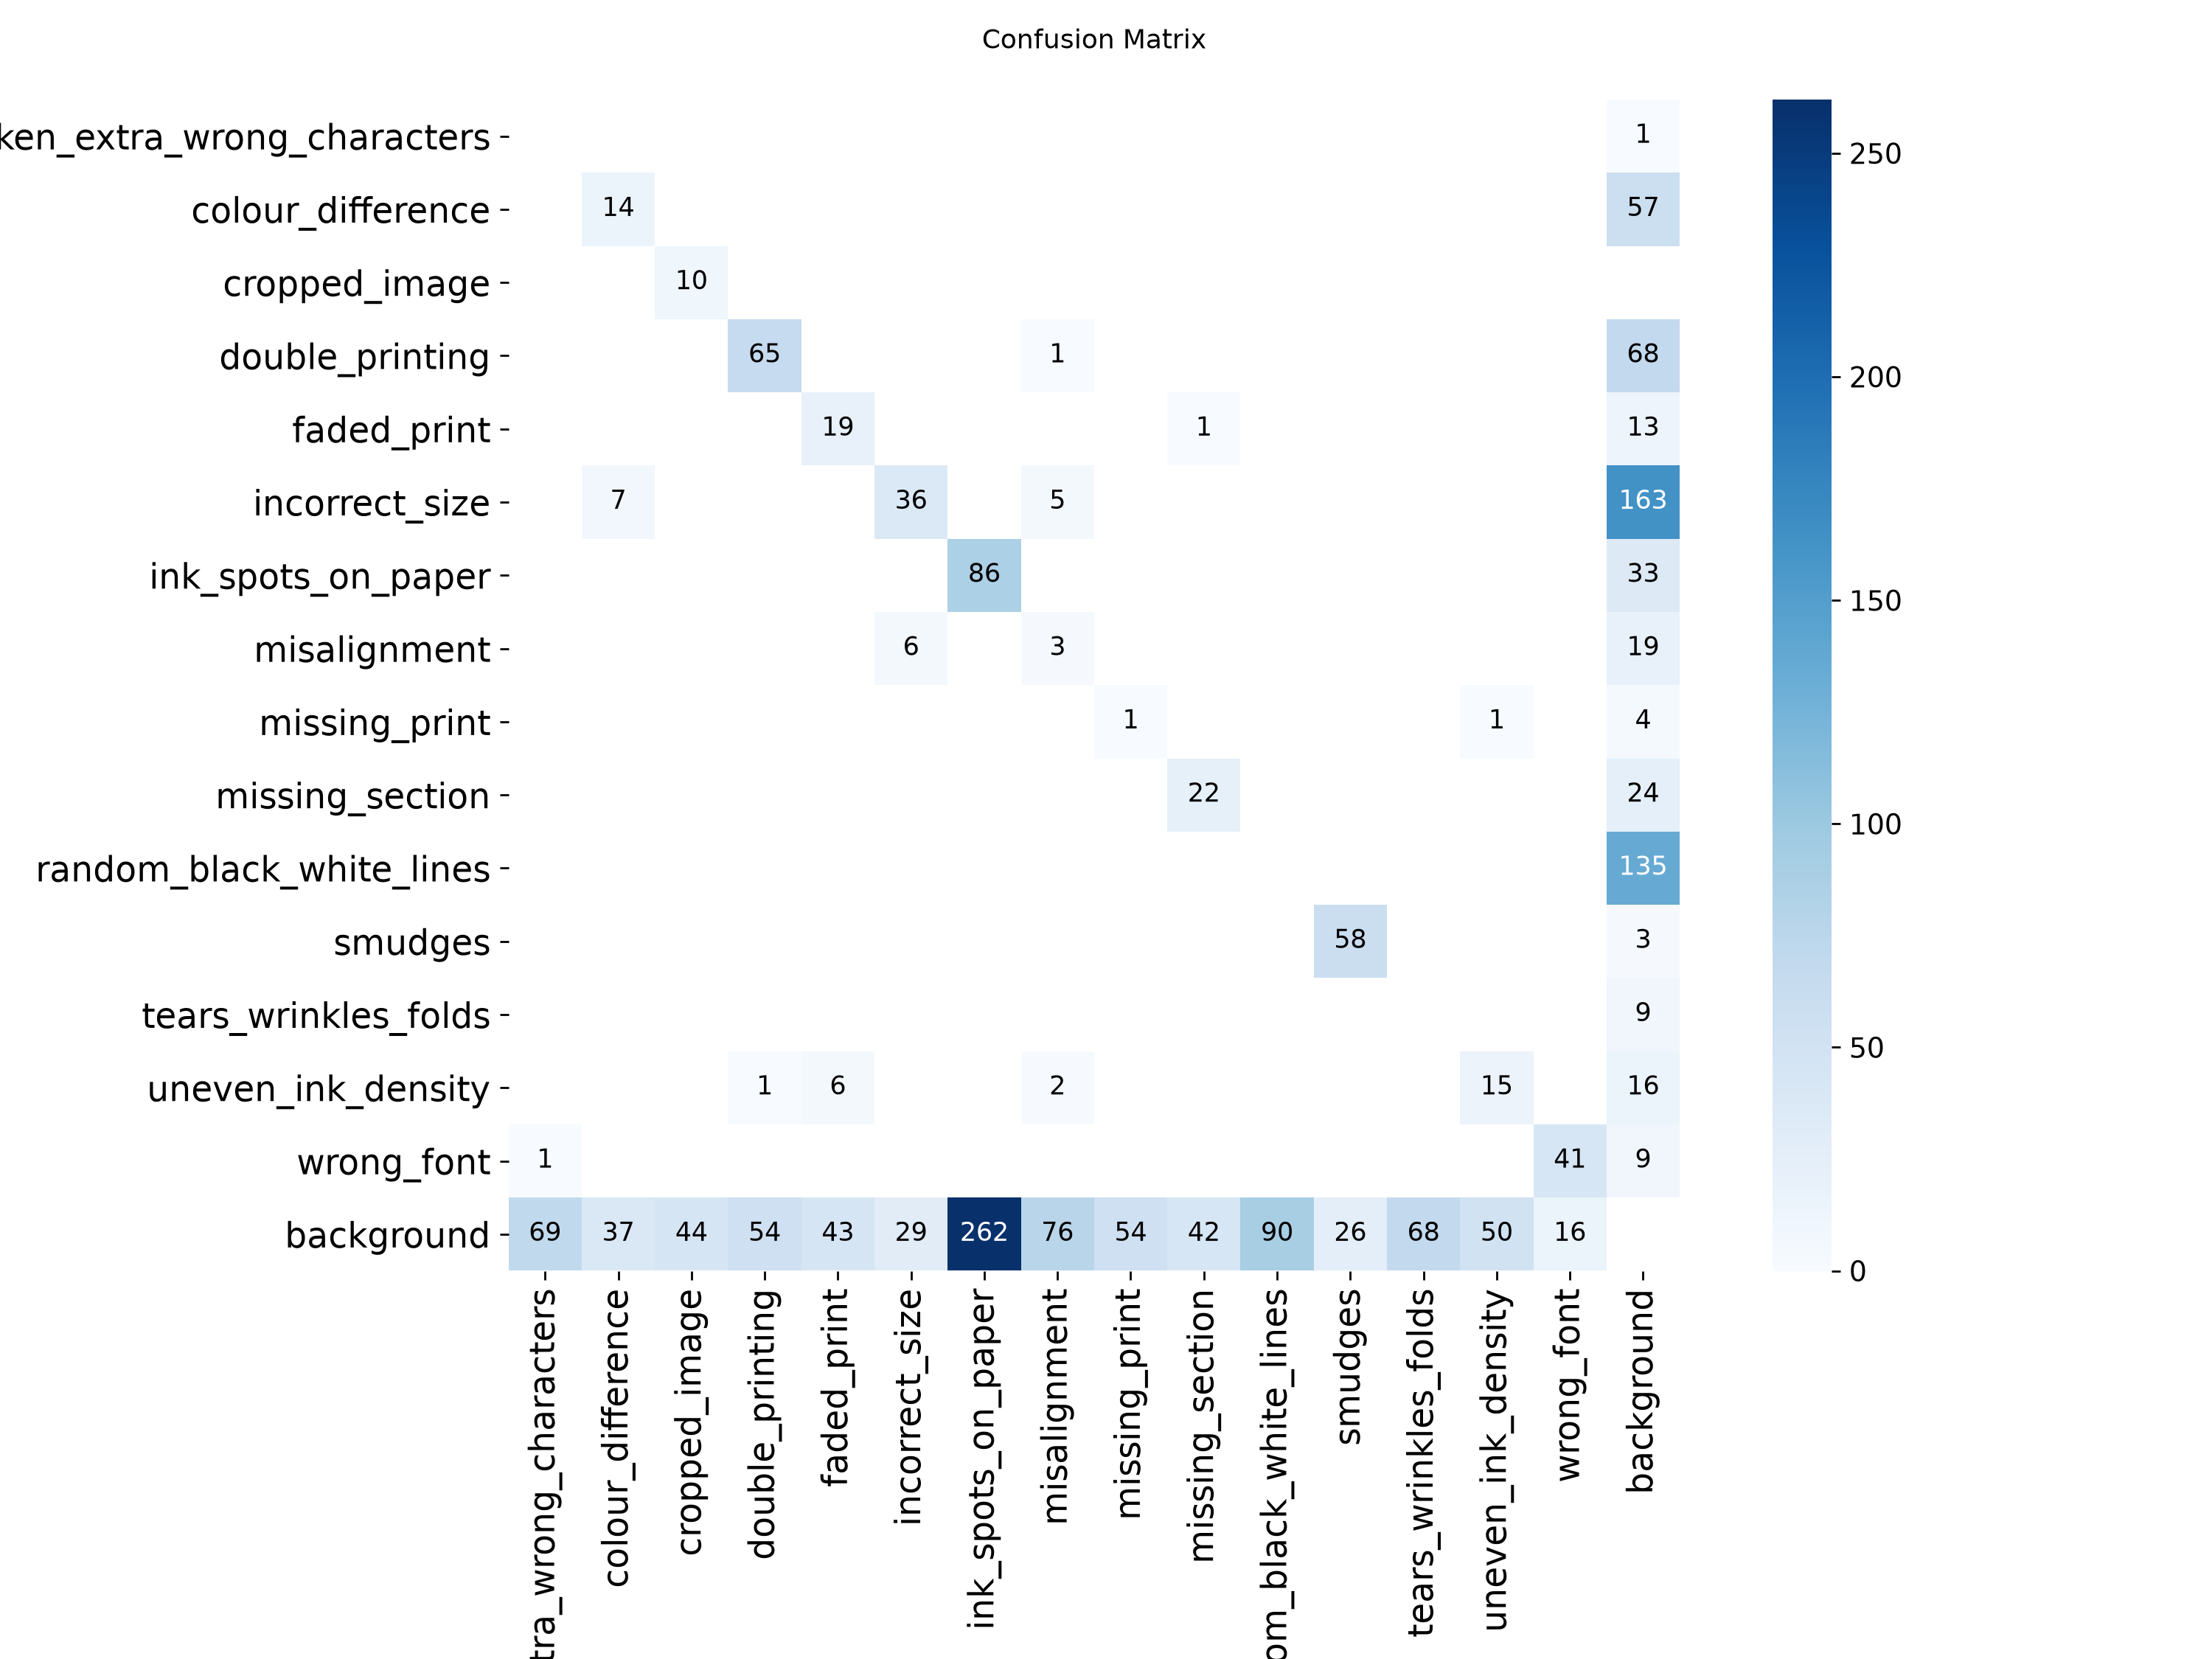

In [23]:
from IPython.display import display, Image

CONFUSION_MATRIX = (
    "/home/23CSU030/Major project phase2/code/runs/val/"
    "baseline_yolo11s_confusion_recovered/confusion_matrix.png"
)

if os.path.isfile(CONFUSION_MATRIX):
    display(Image(filename=CONFUSION_MATRIX))
else:
    print("Confusion matrix was not generated. Check the validation output.")

In [24]:
# Precision-Recall curve, F1 curve, Precision curve, Recall curve (on validation split)
for fname in ["PR_curve.png", "F1_curve.png", "P_curve.png", "R_curve.png"]:
    fpath = os.path.join(TRAIN_RUN_DIR, fname)
    if os.path.exists(fpath):
        print(fname)
        display(Image(filename=fpath))


In [25]:
# A few example validation batches with ground-truth vs. predicted boxes (saved by YOLO11 during training)
for fname in ["val_batch0_labels.jpg", "val_batch0_pred.jpg"]:
    fpath = os.path.join(TRAIN_RUN_DIR, fname)
    if os.path.exists(fpath):
        print(fname)
        display(Image(filename=fpath))


## Step 8 — Locate the best trained weights

YOLO11 saves two checkpoints: `best.pt` (best validation mAP during training) and
`last.pt` (final epoch). We reload `best.pt` into a fresh `YOLO` model for evaluation
and predictions.


In [26]:
BEST_WEIGHTS = os.path.join(TRAIN_RUN_DIR, "weights", "best.pt")
LAST_WEIGHTS = os.path.join(TRAIN_RUN_DIR, "weights", "last.pt")

assert os.path.exists(BEST_WEIGHTS), f"best.pt not found at {BEST_WEIGHTS} — did training finish?"
print("Best weights:", BEST_WEIGHTS)
print("Last weights:", LAST_WEIGHTS)

best_model = YOLO(BEST_WEIGHTS)


Best weights: /home/23CSU030/Major project phase2/code/runs/train/baseline_yolo11s/weights/best.pt
Last weights: /home/23CSU030/Major project phase2/code/runs/train/baseline_yolo11s/weights/last.pt


## Step 9 — Evaluate on the held-out TEST set

Everything so far (training curves, confusion matrix) used the **validation** split,
which YOLO11 checks after every epoch. Now we run a separate evaluation pass on the
**test** split — images that never influenced training or checkpoint selection — using
`model.val(split="test")`.

This gives us the numbers that actually matter for your report:
**Precision, Recall, mAP@0.5, mAP@0.5:0.95**, overall and per class.


In [27]:
TEST_RUN_NAME = RUN_NAME + "_test_eval"

metrics = best_model.val(
    data=FIXED_YAML_PATH,
    split="test",
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    project=os.path.join(RUNS_DIR, "val"),
    name=TEST_RUN_NAME,
    exist_ok=True,
    plots=True,
    save_json=False,
    verbose=True,
)

TEST_EVAL_DIR = os.path.join(RUNS_DIR, "val", TEST_RUN_NAME)
print("\nTest evaluation outputs saved in:", TEST_EVAL_DIR)


Ultralytics 8.4.158 🚀 Python-3.11.9 torch-2.14.0+cu130 CPU (INTEL XEON GOLD 6530)
YOLO11s summary (fused): 100 layers, 9,418,605 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.1 ms, read: 435.8±475.1 MB/s, size: 36.6 KB)


                   all        243        698      0.371      0.279      0.278      0.145
broken_extra_wrong_characters         34         34          0          0    0.00208   0.000252
     colour_difference         27         27       0.15      0.259      0.107     0.0355
         cropped_image         32         32          1      0.123      0.125      0.103
       double_printing         55         68      0.545      0.599      0.516      0.253
           faded_print         31         31      0.534      0.258      0.309      0.179
        incorrect_size         33         34      0.105      0.471      0.332      0.256
    ink_spots_on_paper         33        155      0.526      0.265      0.289      0.066
          misalignment        

### Pull out the overall and per-class metrics

The `ultralytics` Python API exposes metrics as arrays directly on `metrics.box` — no
need to parse printed text. `box.ap_class_index` tells us which class ID each row in
the arrays corresponds to (only classes that actually appear in the test set get a
row), so we map those back onto your 15 class names. We also add an F1-score column
(`F1 = 2 * P * R / (P + R)`), computed the same way as in your YOLOv5s notebook so the
two are comparable.


In [28]:
import numpy as np
import pandas as pd

box = metrics.box
eps = 1e-9

# box.ap_class_index: the class IDs present in the test set (in the order the arrays below use)
# box.p / box.r / box.f1 / box.ap50 / box.ap: precision / recall / F1 / mAP@0.5 / mAP@0.5:0.95 per class
metrics_by_class = {}
for idx, cid in enumerate(box.ap_class_index):
    metrics_by_class[int(cid)] = {
        "precision": float(box.p[idx]),
        "recall": float(box.r[idx]),
        "F1": float(box.f1[idx]),
        "mAP@0.5": float(box.ap50[idx]),
        "mAP@0.5:0.95": float(box.ap[idx]),
    }

rows = []
for cid, cname in enumerate(CLASS_NAMES):
    m = metrics_by_class.get(cid, {"precision": 0.0, "recall": 0.0, "F1": 0.0,
                                    "mAP@0.5": 0.0, "mAP@0.5:0.95": 0.0})
    rows.append({
        "class_name": cname,
        "instances": per_split_counter["test"].get(cid, 0),   # from the Step 4 dataset scan
        "precision": m["precision"],
        "recall": m["recall"],
        "mAP@0.5": m["mAP@0.5"],
        "mAP@0.5:0.95": m["mAP@0.5:0.95"],
        "F1": m["F1"],
    })

classwise_df = pd.DataFrame(rows)
classwise_df


,class_name,instances,precision,recall,mAP@0.5,mAP@0.5:0.95,F1
0,broken_extra_wrong_characters,34,0.000000,0.000000,0.002084,0.000252,0.000000
1,colour_difference,27,0.149509,0.259259,0.106862,0.035547,0.189650
2,cropped_image,32,1.000000,0.122980,0.125000,0.103500,0.219025
3,double_printing,68,0.544820,0.598509,0.516217,0.253053,0.570404
4,faded_print,31,0.533668,0.258065,0.309153,0.179334,0.347897
5,incorrect_size,34,0.105378,0.470588,0.332155,0.255610,0.172197
6,ink_spots_on_paper,155,0.525692,0.264571,0.289371,0.066025,0.351992
7,misalignment,46,0.198503,0.086957,0.113907,0.070233,0.120936
8,missing_print,34,0.000000,0.000000,0.001224,0.000183,0.000000
9,missing_section,33,0.303896,0.333333,0.285262,0.143977,0.317935


In [29]:
# Overall (all-class) results
overall_precision = float(box.mp)
overall_recall    = float(box.mr)
overall_map50     = float(box.map50)
overall_map5095   = float(box.map)
overall_f1        = 2 * overall_precision * overall_recall / (overall_precision + overall_recall + eps)

print("=" * 60)
print("OVERALL TEST SET RESULTS (YOLOv8s baseline)")
print("=" * 60)
print(f"Precision      : {overall_precision:.4f}")
print(f"Recall         : {overall_recall:.4f}")
print(f"mAP@0.5        : {overall_map50:.4f}")
print(f"mAP@0.5:0.95   : {overall_map5095:.4f}")
print(f"F1-score       : {overall_f1:.4f}")

test_img_count = len(glob(os.path.join(DATASET_DIR, "test", "images", "*")))
print(f"Test images    : {test_img_count}")
print(f"Test instances : {int(classwise_df['instances'].sum())}")

OVERALL TEST SET RESULTS (YOLOv8s baseline)
Precision      : 0.3713
Recall         : 0.2789
mAP@0.5        : 0.2777
mAP@0.5:0.95   : 0.1447
F1-score       : 0.3185
Test images    : 243
Test instances : 698


## Step 10 — Class-wise performance table (all 15 classes)

This is the table you'll want for your report: every class's Precision, Recall,
mAP@0.5, mAP@0.5:0.95 and F1, sorted from best to worst by mAP@0.5.
`ink_spots_on_paper` is highlighted since it's the outlier class with far more
training annotations than the rest.


In [30]:
display_df = classwise_df.sort_values("mAP@0.5", ascending=False).reset_index(drop=True)
display_df = display_df[["class_name", "instances", "precision", "recall",
                          "mAP@0.5", "mAP@0.5:0.95", "F1"]]

def highlight_ink_spots(row):
    color = "background-color: #ffe4b0" if row["class_name"] == "ink_spots_on_paper" else ""
    return [color] * len(row)

styled = display_df.style.apply(highlight_ink_spots, axis=1).format({
    "precision": "{:.3f}", "recall": "{:.3f}",
    "mAP@0.5": "{:.3f}", "mAP@0.5:0.95": "{:.3f}", "F1": "{:.3f}",
})
styled


,class_name,instances,precision,recall,mAP@0.5,mAP@0.5:0.95,F1
0,smudges,41,0.947,0.707,0.860,0.423,0.810
1,wrong_font,38,0.793,0.658,0.815,0.343,0.719
2,double_printing,68,0.545,0.599,0.516,0.253,0.570
3,uneven_ink_density,33,0.468,0.424,0.408,0.298,0.445
4,incorrect_size,34,0.105,0.471,0.332,0.256,0.172
5,faded_print,31,0.534,0.258,0.309,0.179,0.348
6,ink_spots_on_paper,155,0.526,0.265,0.289,0.066,0.352
7,missing_section,33,0.304,0.333,0.285,0.144,0.318
8,cropped_image,32,1.000,0.123,0.125,0.103,0.219
9,misalignment,46,0.199,0.087,0.114,0.070,0.121


In [31]:
# Save the class-wise table as a CSV for your report
CLASSWISE_CSV_PATH = os.path.join(TRAIN_RUN_DIR, "classwise_test_metrics.csv")
display_df.to_csv(CLASSWISE_CSV_PATH, index=False)
print("Saved class-wise metrics to:", CLASSWISE_CSV_PATH)


Saved class-wise metrics to: /home/23CSU030/Major project phase2/code/runs/train/baseline_yolo11s/classwise_test_metrics.csv


## Step 11 — ink_spots_on_paper — reported separately (class imbalance note)

Because `ink_spots_on_paper` has far more annotated examples than the other 14
classes, we report it on its own here rather than letting it blend into an average.


In [32]:
ink_row = classwise_df[classwise_df["class_name"] == "ink_spots_on_paper"].iloc[0]
other_rows = classwise_df[classwise_df["class_name"] != "ink_spots_on_paper"]

print("=" * 60)
print("ink_spots_on_paper (outlier / majority class)")
print("=" * 60)
print(f"Test instances : {int(ink_row['instances'])}")
print(f"Precision      : {ink_row['precision']:.4f}")
print(f"Recall         : {ink_row['recall']:.4f}")
print(f"mAP@0.5        : {ink_row['mAP@0.5']:.4f}")
print(f"mAP@0.5:0.95   : {ink_row['mAP@0.5:0.95']:.4f}")
print(f"F1-score       : {ink_row['F1']:.4f}")

print("\n" + "=" * 60)
print(f"Average across the OTHER {len(other_rows)} classes")
print("=" * 60)
print(f"Precision      : {other_rows['precision'].mean():.4f}")
print(f"Recall         : {other_rows['recall'].mean():.4f}")
print(f"mAP@0.5        : {other_rows['mAP@0.5'].mean():.4f}")
print(f"mAP@0.5:0.95   : {other_rows['mAP@0.5:0.95'].mean():.4f}")
print(f"F1-score       : {other_rows['F1'].mean():.4f}")

diff = ink_row["mAP@0.5"] - other_rows["mAP@0.5"].mean()
print(f"\nmAP@0.5 gap (ink_spots_on_paper vs. average of other classes): {diff:+.4f}")
if diff > 0.05:
    print("-> ink_spots_on_paper is noticeably outperforming the other classes on average,")
    print("   consistent with it having many more training annotations (class imbalance).")
elif diff < -0.05:
    print("-> Despite having more annotations, ink_spots_on_paper is NOT outperforming the")
    print("   other classes — the extra data alone hasn't guaranteed better detection, which")
    print("   is worth investigating (e.g. check if this class has harder/more varied instances).")
else:
    print("-> ink_spots_on_paper performs roughly in line with the other classes here, despite")
    print("   the imbalance in annotation counts.")


ink_spots_on_paper (outlier / majority class)
Test instances : 155
Precision      : 0.5257
Recall         : 0.2646
mAP@0.5        : 0.2894
mAP@0.5:0.95   : 0.0660
F1-score       : 0.3520

Average across the OTHER 14 classes
Precision      : 0.3603
Recall         : 0.2799
mAP@0.5        : 0.2769
mAP@0.5:0.95   : 0.1504
F1-score       : 0.2794

mAP@0.5 gap (ink_spots_on_paper vs. average of other classes): +0.0125
-> ink_spots_on_paper performs roughly in line with the other classes here, despite
   the imbalance in annotation counts.


## Step 12 — Confusion matrix and PR/F1 curves (test set)

These come from the `model.val(split="test")` run in Step 9. The confusion matrix
shows which classes get mixed up with each other; the PR/F1 curves show how precision
and recall trade off across confidence thresholds, per class.


In [33]:
print("Test evaluation outputs saved in:", TEST_EVAL_DIR)
print(os.listdir(TEST_EVAL_DIR))


Test evaluation outputs saved in: /home/23CSU030/Major project phase2/code/runs/val/baseline_yolo11s_test_eval
['val_batch0_pred.jpg', 'val_batch1_labels.jpg', 'val_batch1_pred.jpg', 'BoxP_curve.png', 'confusion_matrix.png', 'val_batch0_labels.jpg', 'BoxR_curve.png', 'val_batch2_labels.jpg', 'BoxPR_curve.png', 'val_batch2_pred.jpg', 'confusion_matrix_normalized.png', 'BoxF1_curve.png']


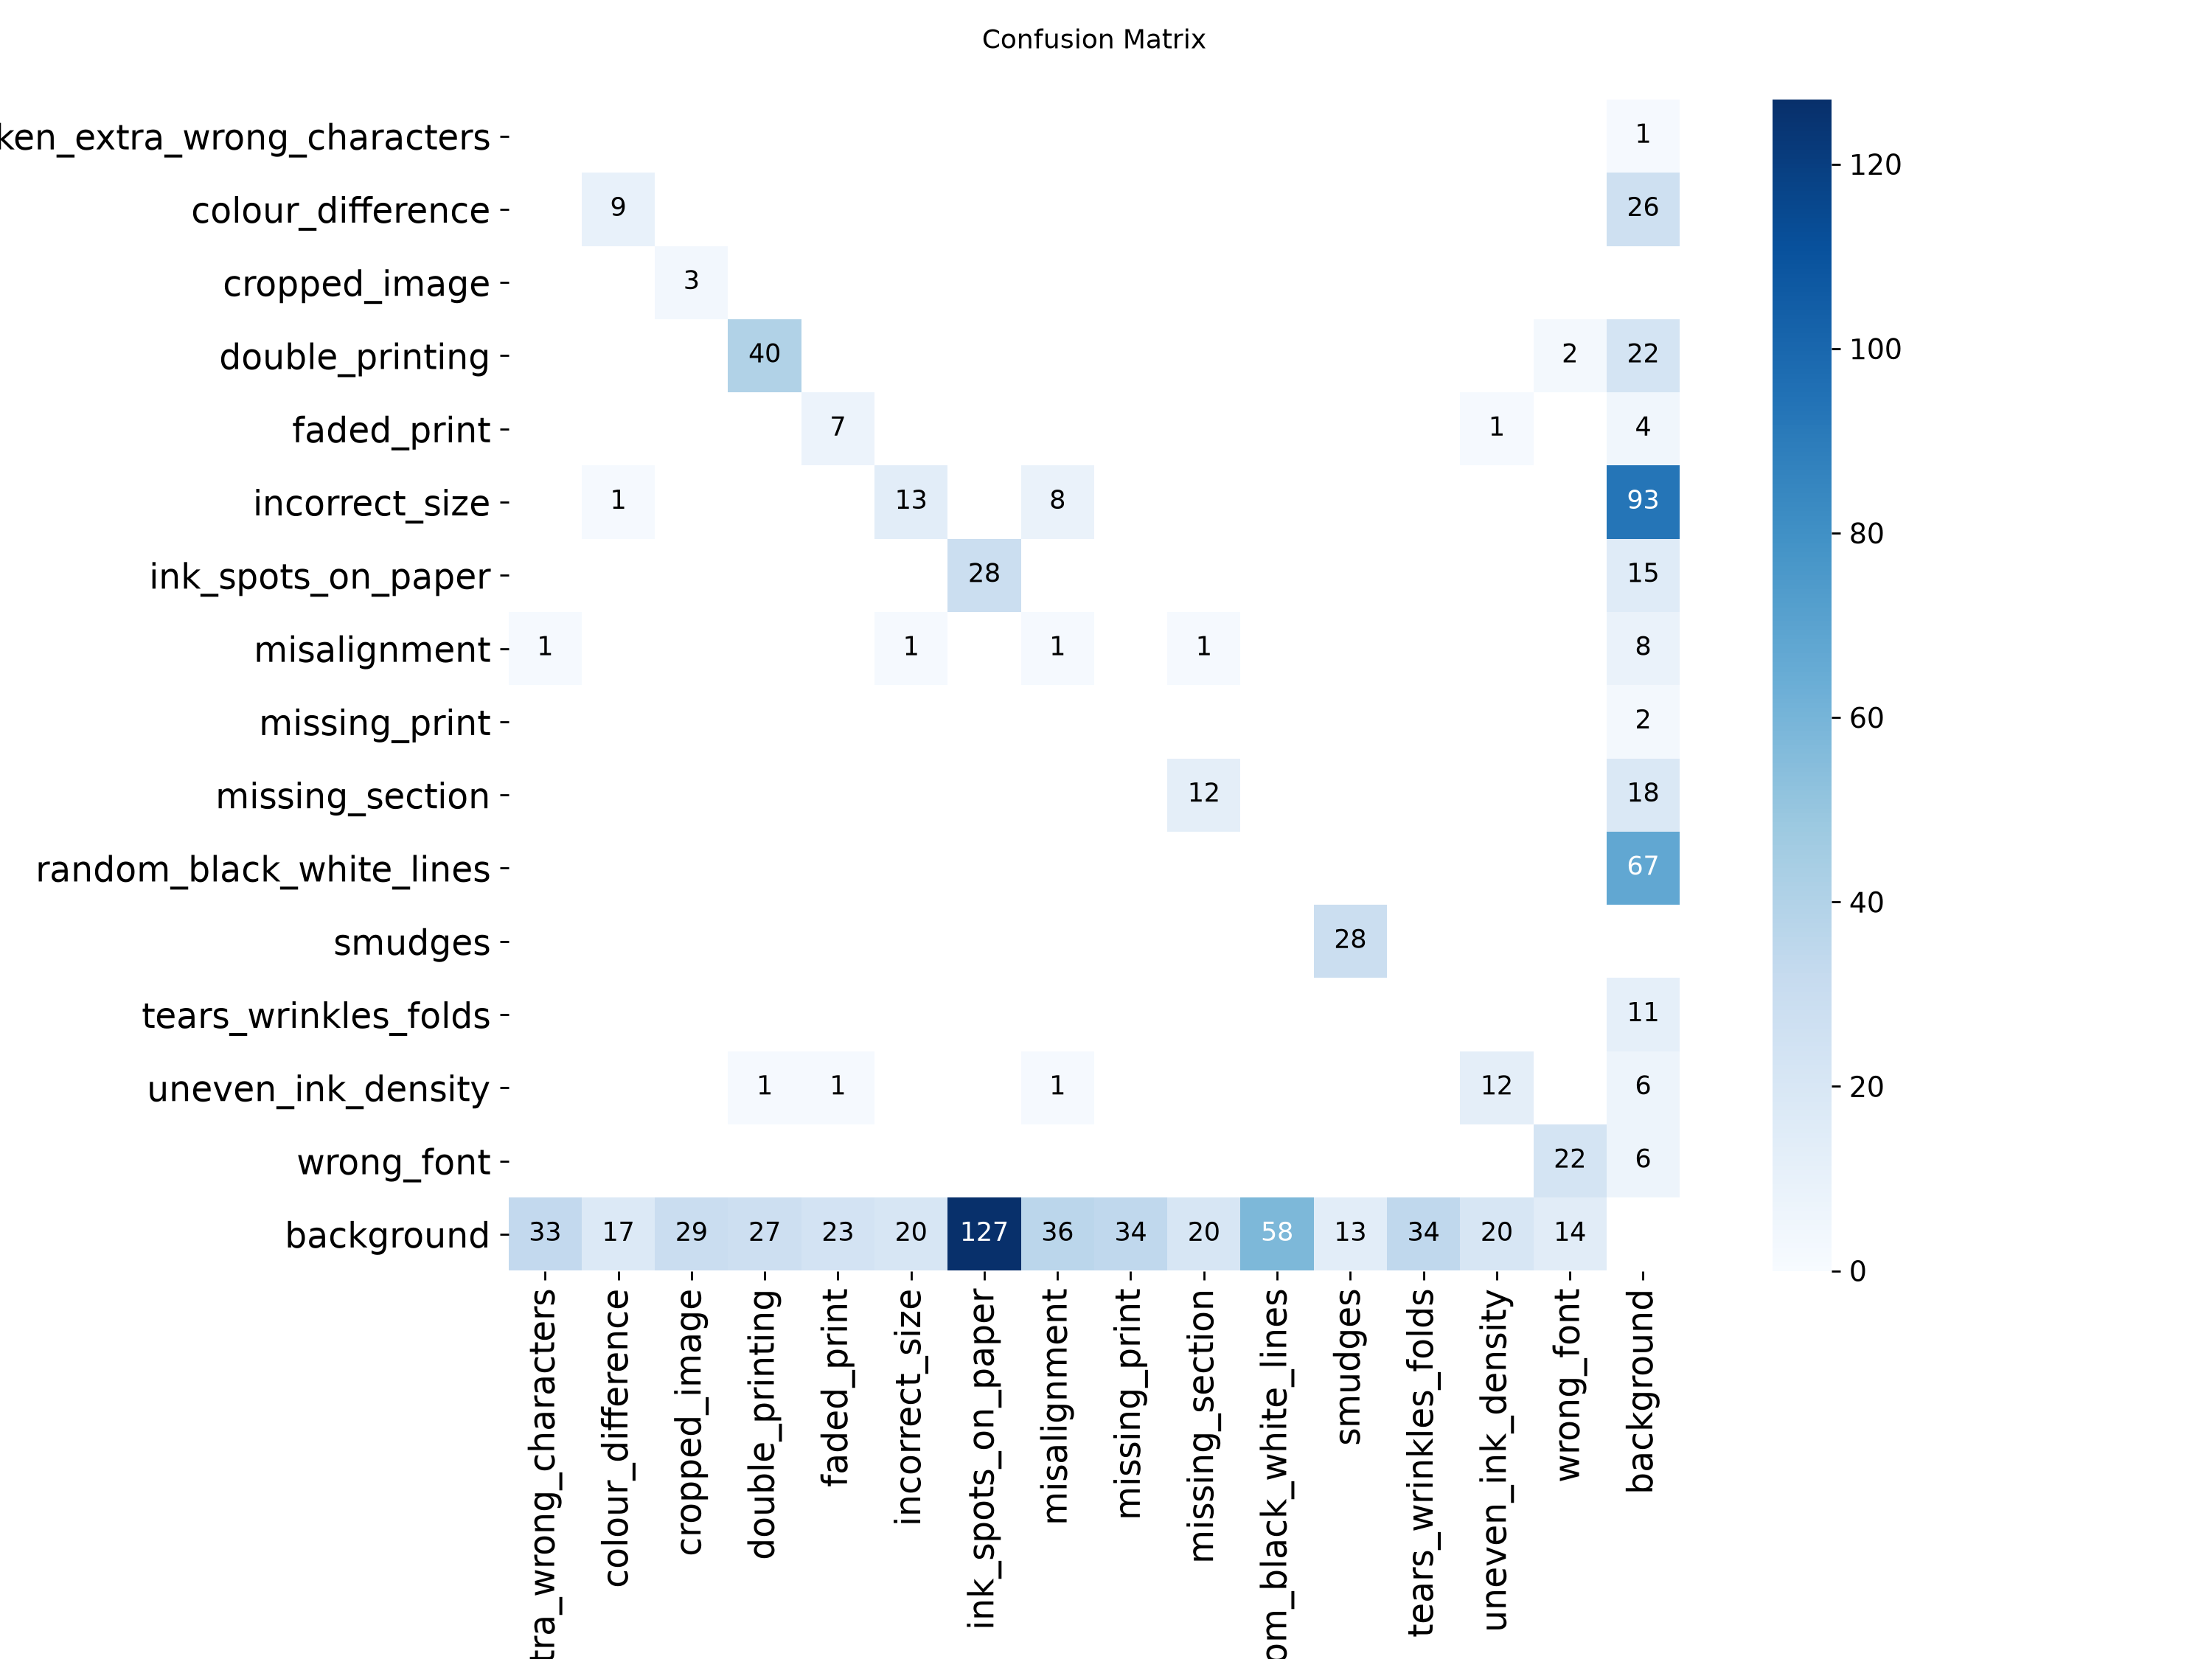

In [34]:
display(Image(filename=os.path.join(TEST_EVAL_DIR, "confusion_matrix.png")))


In [35]:
for fname in ["PR_curve.png", "F1_curve.png", "P_curve.png", "R_curve.png"]:
    fpath = os.path.join(TEST_EVAL_DIR, fname)
    if os.path.exists(fpath):
        print(fname)
        display(Image(filename=fpath))


## Step 13 — Run predictions on test images and save annotated examples

Now we run the trained model on the test images with `.predict()`, which draws
predicted bounding boxes + class labels + confidence scores on each image and saves
them. We then display a handful of examples inline.


In [36]:
PRED_RUN_NAME = RUN_NAME + "_test_predictions"

pred_results = best_model.predict(
    source=os.path.join(DATASET_DIR, "test", "images"),
    imgsz=IMG_SIZE,
    conf=0.25,
    save=True,
    save_txt=True,
    save_conf=True,
    project=os.path.join(RUNS_DIR, "detect"),
    name=PRED_RUN_NAME,
    exist_ok=True,
)

PRED_DIR = os.path.join(RUNS_DIR, "detect", PRED_RUN_NAME)
print("Annotated prediction images saved in:", PRED_DIR)



image 1/243 /home/23CSU030/Major project phase2/Augmented_Dataset/test/images/broken_extra_wrong_characters_0058_jpg.rf.f8b85c469106d60112cbccd0aa3af7dd.jpg: 512x512 (no detections), 570.0ms
image 2/243 /home/23CSU030/Major project phase2/Augmented_Dataset/test/images/broken_extra_wrong_characters_0124_jpg.rf.7fe9d7e42a1a4e67958574d44cf61e64.jpg: 512x512 1 uneven_ink_density, 548.1ms
image 3/243 /home/23CSU030/Major project phase2/Augmented_Dataset/test/images/broken_extra_wrong_characters_0136_jpg.rf.9dce9499d6b4dc0e7db6277521dd2c94.jpg: 512x512 (no detections), 648.2ms
image 4/243 /home/23CSU030/Major project phase2/Augmented_Dataset/test/images/broken_extra_wrong_characters_0139_jpg.rf.bb81d8135eb4b4543c0035497d801635.jpg: 512x512 1 uneven_ink_density, 1896.1ms
image 5/243 /home/23CSU030/Major project phase2/Augmented_Dataset/test/images/colour_difference_0006_jpg.rf.93eab6f1a919019b221ddc4ebe430ac4.jpg: 512x512 (no detections), 1242.7ms
image 6/243 /home/23CSU030/Major project pha

In [37]:
pred_images = sorted(glob(os.path.join(PRED_DIR, "*.jpg")))
print(f"Total annotated test images: {len(pred_images)}")


Total annotated test images: 243


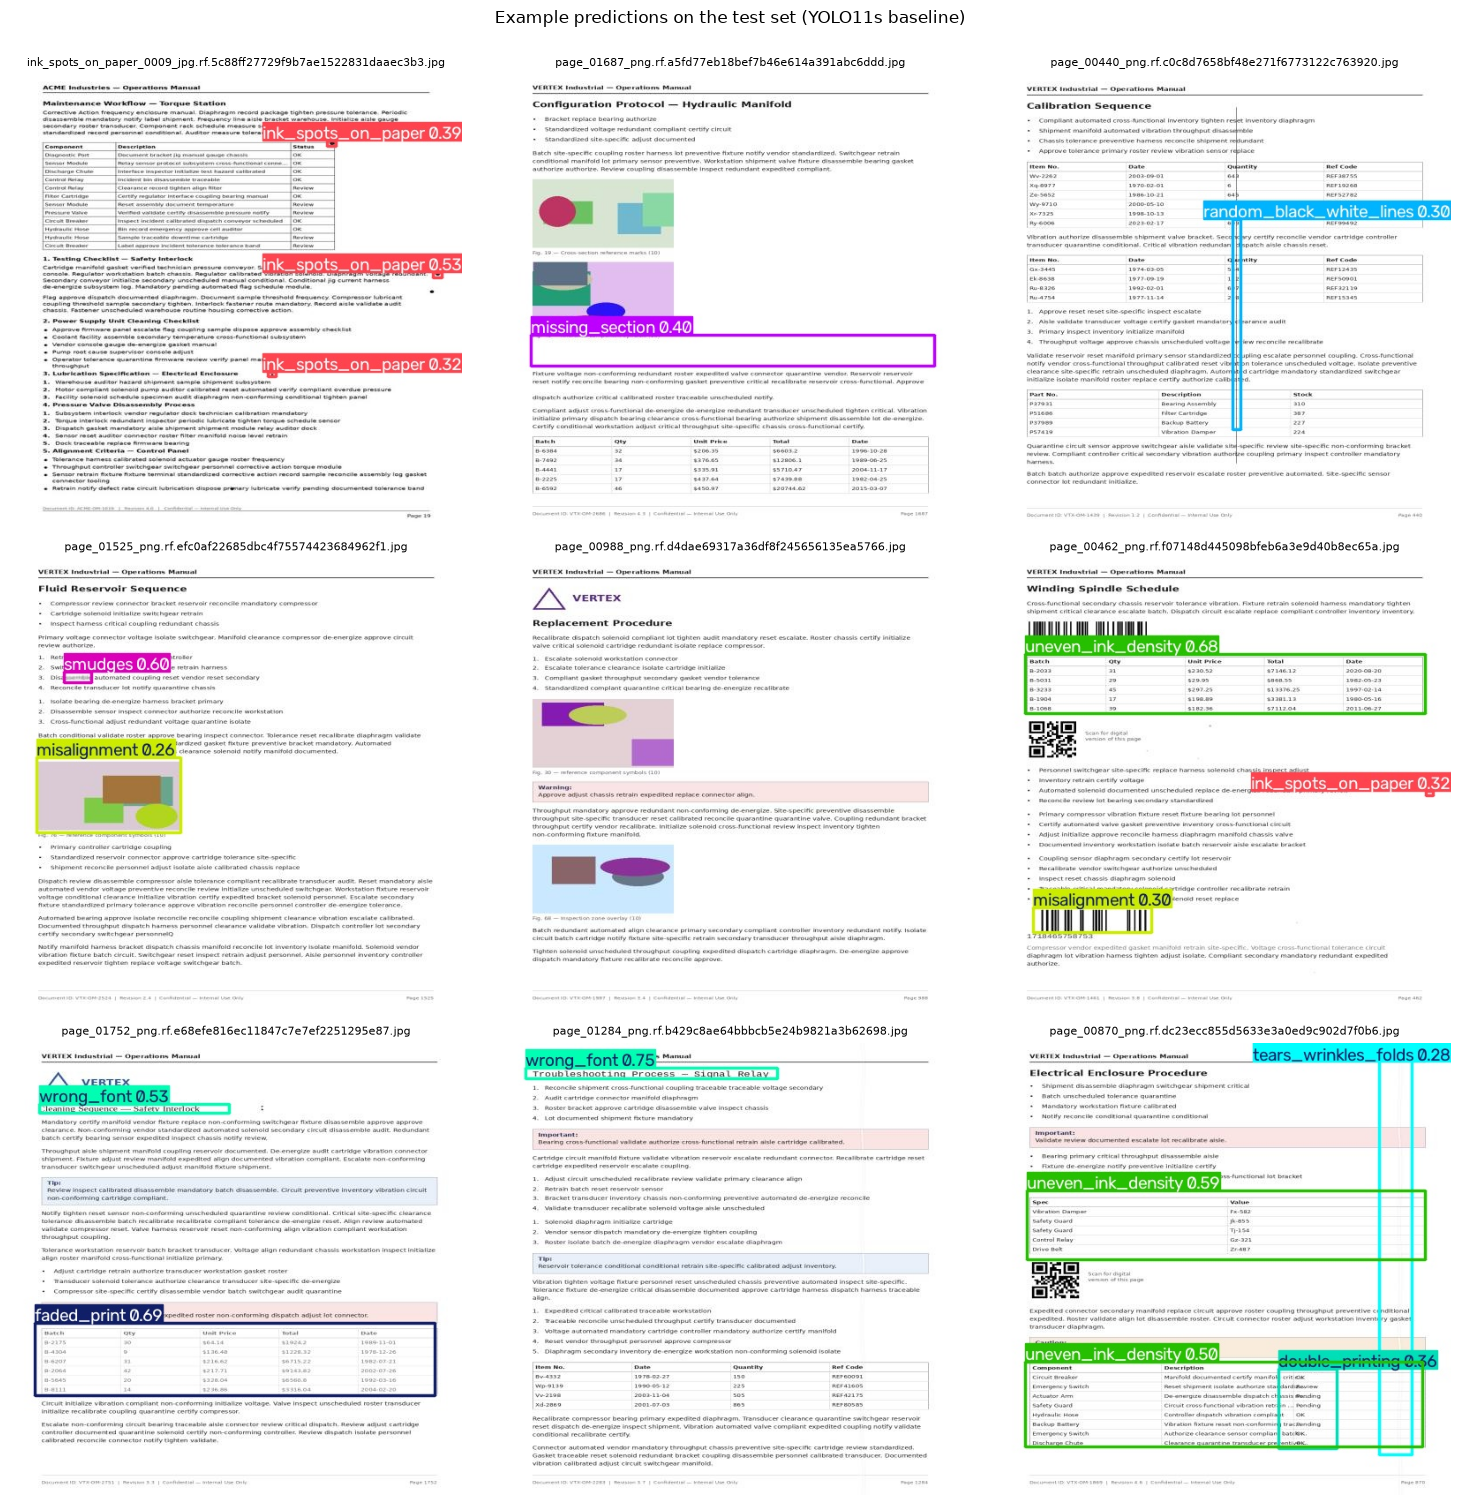

In [38]:
# Display a random sample of annotated predictions
sample_preds = random.sample(pred_images, min(9, len(pred_images)))

cols = 3
rows = (len(sample_preds) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
axes = axes.flatten()

for ax, img_path in zip(axes, sample_preds):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(os.path.basename(img_path), fontsize=8)
    ax.axis("off")

for ax in axes[len(sample_preds):]:
    ax.axis("off")

plt.suptitle("Example predictions on the test set (YOLO11s baseline)", y=1.0)
plt.tight_layout()
plt.show()


## Step 14 — Which defects are detected well, and which perform poorly?

We rank all 15 classes by test mAP@0.5 and clearly separate the strong performers
from the weak ones — the same view as in your YOLOv5s and YOLOv8s notebooks, so you can
compare which classes are hard across all three models vs. which ones only one model
struggles with.


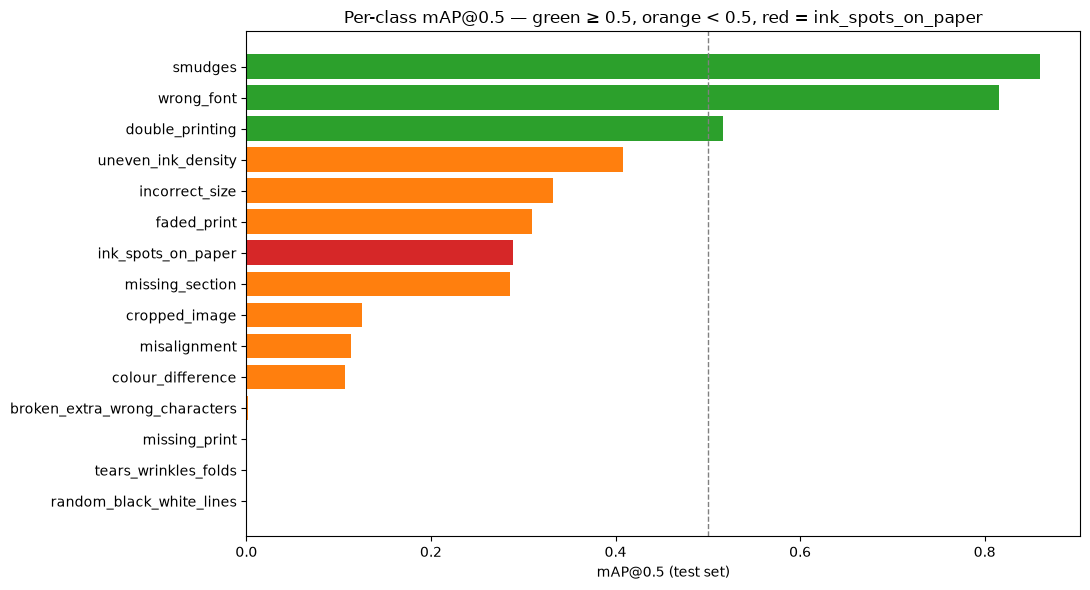

In [39]:
ranked_df = classwise_df.sort_values("mAP@0.5", ascending=False).reset_index(drop=True)

plt.figure(figsize=(11, 6))
colors = ["#d62728" if name == "ink_spots_on_paper" else "#2ca02c" if map50 >= 0.5 else "#ff7f0e"
          for name, map50 in zip(ranked_df["class_name"], ranked_df["mAP@0.5"])]
plt.barh(ranked_df["class_name"], ranked_df["mAP@0.5"], color=colors)
plt.gca().invert_yaxis()
plt.xlabel("mAP@0.5 (test set)")
plt.title("Per-class mAP@0.5 — green ≥ 0.5, orange < 0.5, red = ink_spots_on_paper")
plt.axvline(0.5, color="gray", linestyle="--", linewidth=1)
plt.tight_layout()
plt.show()


In [40]:
N_TOP = 5
N_BOTTOM = 5

print("=" * 60)
print(f"TOP {N_TOP} best-detected defect classes (highest mAP@0.5)")
print("=" * 60)
for _, row in ranked_df.head(N_TOP).iterrows():
    print(f"  {row['class_name']:35s}  mAP@0.5={row['mAP@0.5']:.3f}  "
          f"P={row['precision']:.3f}  R={row['recall']:.3f}  F1={row['F1']:.3f}  "
          f"(n={int(row['instances'])})")

print("\n" + "=" * 60)
print(f"BOTTOM {N_BOTTOM} worst-detected defect classes (lowest mAP@0.5)")
print("=" * 60)
for _, row in ranked_df.tail(N_BOTTOM).sort_values("mAP@0.5").iterrows():
    print(f"  {row['class_name']:35s}  mAP@0.5={row['mAP@0.5']:.3f}  "
          f"P={row['precision']:.3f}  R={row['recall']:.3f}  F1={row['F1']:.3f}  "
          f"(n={int(row['instances'])})")

print("\nNote: classes with very few test instances (small 'n') can have noisy metrics —")
print("check the 'instances' column before drawing strong conclusions about a class.")


TOP 5 best-detected defect classes (highest mAP@0.5)
  smudges                              mAP@0.5=0.860  P=0.947  R=0.707  F1=0.810  (n=41)
  wrong_font                           mAP@0.5=0.815  P=0.793  R=0.658  F1=0.719  (n=38)
  double_printing                      mAP@0.5=0.516  P=0.545  R=0.599  F1=0.570  (n=68)
  uneven_ink_density                   mAP@0.5=0.408  P=0.468  R=0.424  F1=0.445  (n=33)
  incorrect_size                       mAP@0.5=0.332  P=0.105  R=0.471  F1=0.172  (n=34)

BOTTOM 5 worst-detected defect classes (lowest mAP@0.5)
  random_black_white_lines             mAP@0.5=0.000  P=0.000  R=0.000  F1=0.000  (n=58)
  tears_wrinkles_folds                 mAP@0.5=0.000  P=0.000  R=0.000  F1=0.000  (n=34)
  missing_print                        mAP@0.5=0.001  P=0.000  R=0.000  F1=0.000  (n=34)
  broken_extra_wrong_characters        mAP@0.5=0.002  P=0.000  R=0.000  F1=0.000  (n=34)
  colour_difference                    mAP@0.5=0.107  P=0.150  R=0.259  F1=0.190  (n=27)


## Step 15 — Save everything

We zip up the training run (weights, curves, confusion matrix, class-wise CSV) and the
test evaluation + prediction folders, so you have one archive with everything needed
for your report and for comparing against YOLOv5s and YOLOv8s.


In [41]:
import shutil
import json

SAVE_ROOT = os.path.join(PROJECT_DIR, "yolo11s_baseline_results")
os.makedirs(SAVE_ROOT, exist_ok=True)

shutil.copytree(TRAIN_RUN_DIR, os.path.join(SAVE_ROOT, "train"), dirs_exist_ok=True)
shutil.copytree(TEST_EVAL_DIR, os.path.join(SAVE_ROOT, "test_eval"), dirs_exist_ok=True)
shutil.copytree(PRED_DIR, os.path.join(SAVE_ROOT, "test_predictions"), dirs_exist_ok=True)

# Also save the overall + class-wise metrics as plain CSV/JSON at the top level
display_df.to_csv(os.path.join(SAVE_ROOT, "classwise_test_metrics.csv"), index=False)
with open(os.path.join(SAVE_ROOT, "overall_test_metrics.json"), "w") as f:
    json.dump({
        "precision": overall_precision,
        "recall": overall_recall,
        "mAP@0.5": overall_map50,
        "mAP@0.5:0.95": overall_map5095,
        "F1": overall_f1,
        "test_images": test_img_count,
        "test_instances": int(classwise_df["instances"].sum()),
    }, f, indent=2)

zip_path = shutil.make_archive(os.path.join(PROJECT_DIR, "yolo11s_baseline_results"), "zip", SAVE_ROOT)
print("Saved everything to:", zip_path)


Saved everything to: /home/23CSU030/Major project phase2/code/yolo11s_baseline_results.zip


In [42]:
# No Colab download step needed — the results zip already sits on the server.
print("Results zip saved at:", zip_path)
# Copy it to your own machine from a LOCAL terminal, e.g.:
# scp 23CSU030@<server-address>:"${zip_path}" .


Results zip saved at: /home/23CSU030/Major project phase2/code/yolo11s_baseline_results.zip


In [43]:
# Optional: also copy everything to a backup folder on the server (Google Drive not applicable here)
if SAVE_TO_DRIVE:
    os.makedirs(DRIVE_SAVE_FOLDER, exist_ok=True)
    shutil.copytree(SAVE_ROOT, DRIVE_SAVE_FOLDER, dirs_exist_ok=True)
    print("Copied results to backup folder:", DRIVE_SAVE_FOLDER)
else:
    print("SAVE_TO_DRIVE is False — skipping. Set it to True in Step 0 to enable this.")


SAVE_TO_DRIVE is False — skipping. Set it to True in Step 0 to enable this.


## Summary & next steps

You now have a complete **YOLO11s baseline** for your printing-defect dataset, built
the same way as your YOLOv5s and YOLOv8s baselines. That means **Phase 3 is done** —
you have three directly-comparable baselines:

- Overall test-set Precision, Recall, mAP@0.5, mAP@0.5:0.95, and F1 (Step 9)
- A full class-wise performance table for all 15 classes (Step 10)
- `ink_spots_on_paper` reported separately, with its class-imbalance context noted
  (Step 11)
- Confusion matrix + PR/F1/P/R curves on the test set (Step 12)
- Annotated example predictions on test images (Step 13)
- A ranked list of best- vs. worst-detected defect classes (Step 14)
- Everything zipped and saved (Step 15)

**According to your plan, next you'll:**
- **Phase 4:** Line up the class-wise tables from all three baselines
  (YOLOv5s / YOLOv8s / YOLO11s) side by side and identify which defects are
  *consistently* difficult, regardless of model — those are your genuinely hard
  classes, not just a quirk of one architecture.
- **Phase 5:** Use those consistently difficult classes to motivate your novelty —
  e.g. the *defect-aware spatial-frequency feature enhancement* idea from your notes.
- **Phase 6:** Once the novelty is implemented, re-run this same evaluation pipeline
  on it so its numbers are directly comparable to these three baselines.
- **Phase 7:** Once you're ready to test augmentation, remove (or reduce) the
  `NO_AUGMENTATION_PARAMS` overrides in Step 6 (and the equivalent in the other two
  notebooks) and re-run, then compare results specifically for the classes that
  struggled here.
